# Lab 4: Explainable and Privacy-Aware AI Threat Alert

**Course:** ENSP355 – AI in Cyber Security  
**Platform:** Jupyter Notebook / Google Colab  
**Aim:** Generate confidence-aware login predictions, explain feature importance, test sensitivity, mask identifiers, and create responsible alerts.

> **Dataset/model note:** The assignment says to reuse the small login-activity model and dataset from Lab 2, but those files were not included with this Lab 4 PDF. To keep this notebook runnable, it creates a small, clearly labelled illustrative training dataset and trains a Decision Tree. If your Lab 2 dataset/model is available, replace the illustrative training data and retrain the model before submission. The five assessment records below follow the Lab 4 manual exactly.

## Learning outcomes
- Explain predictions with confidence scores.
- Interpret feature importance without treating it as causation.
- Observe the effect of changing one input.
- Mask IP addresses and account identifiers.
- Generate alerts that support human review rather than automatic punishment.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

pd.set_option("display.max_colwidth", 100)
RANDOM_STATE = 42

## 1. Prepare training data and train the Lab 2-style Decision Tree

The manual refers to a supplied Lab 2 model but does not attach it. The following compact synthetic dataset is only a runnable stand-in. Labels are illustrative: `Normal` and `Suspicious`. Features match the four numeric fields used in the Lab 4 task.

In [2]:
training_data = pd.DataFrame([
    [0, 10, 0, 40, "Normal"],
    [1, 14, 0, 80, "Normal"],
    [2, 9, 0, 80, "Normal"],
    [0, 18, 0, 120, "Normal"],
    [3, 11, 0, 160, "Normal"],
    [1, 15, 1, 90, "Normal"],
    [4, 23, 1, 400, "Suspicious"],
    [7, 2, 1, 150, "Suspicious"],
    [6, 1, 1, 620, "Suspicious"],
    [5, 23, 0, 550, "Suspicious"],
    [8, 3, 1, 700, "Suspicious"],
    [5, 22, 1, 300, "Suspicious"],
    [0, 2, 0, 30, "Normal"],
    [2, 20, 0, 200, "Normal"],
    [6, 10, 1, 100, "Suspicious"],
    [1, 4, 1, 520, "Suspicious"],
], columns=["failed_logins", "login_hour", "new_device", "download_mb", "label"])

features = ["failed_logins", "login_hour", "new_device", "download_mb"]
X_train = training_data[features]
y_train = training_data["label"]

model = DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE)
model.fit(X_train, y_train)

print("Training rows:", len(training_data))
print("Classes:", list(model.classes_))
print("Training accuracy (illustrative data):", round(accuracy_score(y_train, model.predict(X_train)), 3))

Training rows: 16
Classes: ['Normal', 'Suspicious']
Training accuracy (illustrative data): 1.0


## 2. Q1 – Baseline predictions with confidence (5 marks)

Create the five sanitized sample records from the lab manual. Confidence is the maximum predicted class probability; it is not a guarantee that the prediction is correct.

In [3]:
samples = pd.DataFrame([
    {"account_id": "ACC-1001", "ip_address": "192.168.10.24",
     "failed_logins": 0, "login_hour": 10, "new_device": 0, "download_mb": 40},
    {"account_id": "ACC-1002", "ip_address": "10.0.4.18",
     "failed_logins": 7, "login_hour": 2, "new_device": 1, "download_mb": 150},
    {"account_id": "ACC-1003", "ip_address": "172.16.8.90",
     "failed_logins": 1, "login_hour": 15, "new_device": 0, "download_mb": 720},
    {"account_id": "ACC-1004", "ip_address": "192.168.20.11",
     "failed_logins": 4, "login_hour": 23, "new_device": 1, "download_mb": 400},
    {"account_id": "ACC-1005", "ip_address": "10.1.1.9",
     "failed_logins": 2, "login_hour": 9, "new_device": 0, "download_mb": 80},
])

samples["prediction"] = model.predict(samples[features])
samples["confidence"] = model.predict_proba(samples[features]).max(axis=1).round(3)

baseline_view = samples[["account_id", "ip_address"] + features + ["prediction", "confidence"]]
display(baseline_view)

lowest_idx = samples["confidence"].idxmin()
print("Lowest-confidence record:", samples.loc[lowest_idx, "account_id"],
      "with confidence", samples.loc[lowest_idx, "confidence"])

,account_id,ip_address,failed_logins,login_hour,new_device,download_mb,prediction,confidence
0,ACC-1001,192.168.10.24,0,10,0,40,Normal,1.0
1,ACC-1002,10.0.4.18,7,2,1,150,Suspicious,1.0
2,ACC-1003,172.16.8.90,1,15,0,720,Suspicious,1.0
3,ACC-1004,192.168.20.11,4,23,1,400,Suspicious,1.0
4,ACC-1005,10.1.1.9,2,9,0,80,Normal,1.0


Lowest-confidence record: ACC-1001 with confidence 1.0


**Interpretation:** Confidence is the model's estimated probability for its selected class. It is not certainty because the model learned from limited illustrative examples and may not represent real-world login behaviour.

## 3. Q2 – Feature importance and explanation (10 marks)

,feature,importance
0,failed_logins,0.777778
1,download_mb,0.222222
2,login_hour,0.000000
3,new_device,0.000000


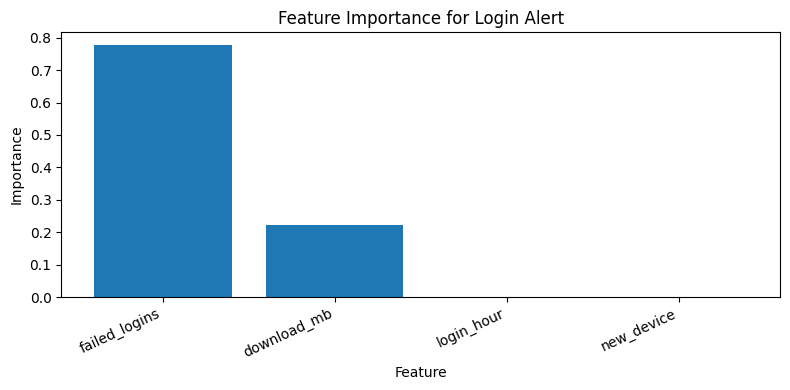

Top-three feature explanations:
- failed_logins: importance = 0.778; this feature contributed to the tree's splits.
- download_mb: importance = 0.222; this feature contributed to the tree's splits.
- login_hour: importance = 0.000; this feature contributed to the tree's splits.


In [4]:
importance = pd.DataFrame({
    "feature": features,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False).reset_index(drop=True)

display(importance)

plt.figure(figsize=(8, 4))
plt.bar(importance["feature"], importance["importance"])
plt.title("Feature Importance for Login Alert")
plt.ylabel("Importance")
plt.xlabel("Feature")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

print("Top-three feature explanations:")
for _, row in importance.head(3).iterrows():
    print(f"- {row['feature']}: importance = {row['importance']:.3f}; "
          "this feature contributed to the tree's splits.")

**Caution:** Feature importance describes how the trained model used inputs; it does not prove that a feature causes suspicious activity. Importance can change with the training data and model settings.

## 4. Q3 – Controlled sensitivity test (10 marks)

The fifth baseline record is copied. Exactly one feature is changed: `failed_logins` changes from 2 to 8. All other feature values remain fixed.

In [5]:
baseline = samples.iloc[[4]][features].copy()
changed = baseline.copy()
changed.loc[changed.index[0], "failed_logins"] = 8

baseline_prediction = model.predict(baseline)[0]
baseline_confidence = model.predict_proba(baseline).max()

changed_prediction = model.predict(changed)[0]
changed_confidence = model.predict_proba(changed).max()

sensitivity_result = pd.DataFrame([
    {"case": "Baseline", **baseline.iloc[0].to_dict(),
     "prediction": baseline_prediction, "confidence": round(float(baseline_confidence), 3)},
    {"case": "Changed failed_logins 2 → 8", **changed.iloc[0].to_dict(),
     "prediction": changed_prediction, "confidence": round(float(changed_confidence), 3)}
])
display(sensitivity_result)

,case,failed_logins,login_hour,new_device,download_mb,prediction,confidence
0,Baseline,2,9,0,80,Normal,1.0
1,Changed failed_logins 2 → 8,8,9,0,80,Suspicious,1.0


**Sensitivity interpretation (3–5 lines):** Only the failed-login count was changed, from 2 to 8; the other three inputs were held constant. Compare the two rows above to see whether the predicted class and confidence changed. If the decision changes, the model is sensitive to this input in this case, potentially because of a learned tree threshold. This controlled example does not establish how a real security system would behave.

## 5. Q4 – Privacy masking and responsible-use rules (5 marks)

In [6]:
def mask_ip(ip):
    parts = str(ip).split(".")
    if len(parts) == 4:
        return f"{parts[0]}.{parts[1]}.xxx.xxx"
    return "<MASKED_IP>"

def mask_account(account_id):
    value = str(account_id)
    if len(value) <= 6:
        return "*" * len(value)
    return value[:4] + "***" + value[-2:]

samples["masked_ip"] = samples["ip_address"].apply(mask_ip)
samples["masked_account"] = samples["account_id"].apply(mask_account)

masked_view = samples[[
    "masked_account", "masked_ip", "prediction", "confidence"
]]
display(masked_view)

privacy_rules = [
    "Mask identifiers before displaying or exporting reports.",
    "Use sanitized data in classroom notebooks and demonstrations.",
    "Restrict access to unmasked records to authorized personnel only.",
    "Require human review before high-impact security action."
]
print("Privacy and responsible-use rules:")
for rule in privacy_rules:
    print("-", rule)

,masked_account,masked_ip,prediction,confidence
0,ACC-***01,192.168.xxx.xxx,Normal,1.0
1,ACC-***02,10.0.xxx.xxx,Suspicious,1.0
2,ACC-***03,172.16.xxx.xxx,Suspicious,1.0
3,ACC-***04,192.168.xxx.xxx,Suspicious,1.0
4,ACC-***05,10.1.xxx.xxx,Normal,1.0


Privacy and responsible-use rules:
- Mask identifiers before displaying or exporting reports.
- Use sanitized data in classroom notebooks and demonstrations.
- Restrict access to unmasked records to authorized personnel only.
- Require human review before high-impact security action.


**Privacy check:** The report view above uses masked account IDs and IP addresses. Do not include the raw `account_id` or `ip_address` columns in screenshots or exported reports.

## 6. Q5 – Responsible alert generation (10 marks)

In [7]:
def numeric_reason(row):
    reasons = []
    if row["failed_logins"] >= 5:
        reasons.append("many failed logins")
    if row["new_device"] == 1:
        reasons.append("new device")
    if row["login_hour"] < 6 or row["login_hour"] > 22:
        reasons.append("unusual login time")
    if row["download_mb"] >= 500:
        reasons.append("large data download")
    return ", ".join(reasons) if reasons else "no strong warning"

def make_alert(row):
    reason = numeric_reason(row)

    if row["prediction"] == "Suspicious":
        severity = "High"
        action = "Verify, contain if required, and report."
    elif row["confidence"] < 0.70:
        severity = "Medium"
        action = "Send for analyst review before action."
    else:
        severity = "Low"
        action = "Continue normal monitoring."

    human_review = "Yes" if severity in ["High", "Medium"] else "No"
    return pd.Series({
        "severity": severity,
        "reason": reason,
        "recommended_action": action,
        "human_review": human_review
    })

alert_fields = samples.apply(make_alert, axis=1)
samples[alert_fields.columns] = alert_fields

final_alerts = samples[[
    "masked_account", "prediction", "confidence", "severity",
    "reason", "recommended_action", "human_review"
]]
display(final_alerts)

,masked_account,prediction,confidence,severity,reason,recommended_action,human_review
0,ACC-***01,Normal,1.0,Low,no strong warning,Continue normal monitoring.,No
1,ACC-***02,Suspicious,1.0,High,"many failed logins, new device, unusual login time","Verify, contain if required, and report.",Yes
2,ACC-***03,Suspicious,1.0,High,large data download,"Verify, contain if required, and report.",Yes
3,ACC-***04,Suspicious,1.0,High,"new device, unusual login time","Verify, contain if required, and report.",Yes
4,ACC-***05,Normal,1.0,Low,no strong warning,Continue normal monitoring.,No


**Human-review condition:** Human review is set to **Yes** for High- and Medium-severity alerts. The prototype does not automatically punish users or block accounts.

**Limitation:** This is a small classroom Decision Tree trained on illustrative synthetic data. It may produce inaccurate or biased results and must not be used as a production security control without representative data, validation, monitoring, and human oversight.

## 7. Conclusion

This lab produced five baseline login predictions with confidence, ranked the model's feature importance, tested sensitivity by changing only `failed_logins`, masked account and IP identifiers, and generated alerts with severity, reasons, recommended actions, and human-review status. The results demonstrate how explanations and privacy controls can make AI-assisted security alerts more accountable. Predictions remain decision-support signals, not proof of malicious activity.

## 8. Submission checklist
- [x] Five baseline predictions and confidence values.
- [x] Feature-importance table and chart.
- [x] Controlled before/after sensitivity result.
- [x] Masked identifiers and four privacy rules.
- [x] Final alert with severity, reason, action, and human review.
- [x] Conclusion and limitation.
- [ ] Run all notebook cells and save the executed notebook.
- [ ] If available, replace illustrative training data with the actual Lab 2 dataset/model.
- [ ] Upload the project to GitHub and paste your GitHub/Colab link in your lab submission.